# 05. Who Stays Local? Self-Containment, Trends and Data Validation

**Data sources:** `od_home_visits_kapanewon_monthly.csv`, `od_origin_homes_monthly.csv`, `home_maids_vs_population_kapanewon.csv`

**Questions**
1. How self-contained is each kapanewon (share of residents who stay in their home kapanewon by day)?
2. How much does each regency visit Kota Yogyakarta, and is that stable over the five months?
3. Can we trust the data? Do device home locations match official population?

In [1]:
# @title 0. Setup (jalankan sekali, otomatis di Google Colab)
# Di Colab: membuat folder kerja, menulis modul helper, dan mengunduh data dari Zenodo.
# Di laptop (repo GitHub): sel ini tidak melakukan apa-apa.
import os, sys, hashlib
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    BASE = "/content/jogjapulse"
    for d in ["src", "data", "figures", "notebooks"]:
        os.makedirs(f"{BASE}/{d}", exist_ok=True)
    open(f"{BASE}/src/__init__.py", "w").close()
    with open(f"{BASE}/src/jogjapulse.py", "w") as f:
        f.write('"""\nShared helpers for the JogjaPulse human mobility project.\n\nAll notebooks import from here so that loading, cleaning and normalisation\nare done the same way everywhere.\n\nDataset: Widyawan et al. (2026). JogjaPulse: An Aggregated Spatio-Temporal\nMobility Dataset for Yogyakarta, Indonesia. Zenodo.\nhttps://doi.org/10.5281/zenodo.23157460  (CC BY 4.0)\n"""\nfrom __future__ import annotations\n\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\n# --------------------------------------------------------------------------\n# Paths\n# --------------------------------------------------------------------------\nROOT = Path(__file__).resolve().parents[1]\nDATA_DIR = ROOT / "data"\nFIG_DIR = ROOT / "figures"\nFIG_DIR.mkdir(exist_ok=True)\n\n# --------------------------------------------------------------------------\n# Constants from the dataset README\n# --------------------------------------------------------------------------\nGOOD_PERIOD_END = "2022-02-28"      # OD flows after this are reduced quality\nSAMPLE_BREAKS = ["2022-01-01", "2022-02-16"]  # abrupt drops in device sample\nANOMALY_DAYS = ["2022-03-08"]       # one-day delivery issue\nNIGHT_HOURS = list(range(0, 6))     # 00:00-05:59 WIB\nDAY_HOURS = list(range(10, 17))     # 10:00-16:59 WIB\nHOLIDAY_WINDOW = ("2021-12-24", "2022-01-02")  # Christmas and New Year\nKAB_ORDER = ["YOGYAKARTA", "SLEMAN", "BANTUL", "KULON PROGO", "GUNUNGKIDUL"]\nDOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]\n\n\ndef _path(name: str) -> Path:\n    p = DATA_DIR / name\n    if not p.exists():\n        raise FileNotFoundError(\n            f"{p} not found. Run `python scripts/download_data.py` first "\n            "or download the CSV files from Zenodo into the data/ folder."\n        )\n    return p\n\n\n# --------------------------------------------------------------------------\n# Loaders\n# --------------------------------------------------------------------------\ndef load_hourly(drop_anomalies: bool = True) -> pd.DataFrame:\n    """Kapanewon x hour presence (n_maids, n_pings)."""\n    df = pd.read_csv(_path("presence_kapanewon_hourly.csv"),\n                     dtype={"kab_code": str, "kapanewon_code": str})\n    df["date"] = pd.to_datetime(df["date"])\n    if drop_anomalies:\n        df = df[~df["date"].isin(pd.to_datetime(ANOMALY_DAYS))]\n    df["dow"] = df["date"].dt.dayofweek          # 0 = Monday\n    df["is_weekend"] = df["dow"] >= 5\n    df["month"] = df["date"].dt.to_period("M").astype(str)\n    return df\n\n\ndef load_cells(drop_anomalies: bool = True) -> pd.DataFrame:\n    """500 m grid cell x day presence (n_maids)."""\n    df = pd.read_csv(_path("presence_cell500m_daily.csv"))\n    df["date"] = pd.to_datetime(df["date"])\n    if drop_anomalies:\n        df = df[~df["date"].isin(pd.to_datetime(ANOMALY_DAYS))]\n    return df\n\n\ndef load_od() -> pd.DataFrame:\n    """Monthly home-based OD visitor counts, joined with origin denominators."""\n    od = pd.read_csv(_path("od_home_visits_kapanewon_monthly.csv"),\n                     dtype={"origin_code": str, "dest_code": str,\n                            "origin_kab_code": str, "dest_kab_code": str})\n    org = pd.read_csv(_path("od_origin_homes_monthly.csv"),\n                      dtype={"origin_code": str, "origin_kab_code": str})\n    od = od.merge(org[["month", "origin_code", "n_homed_maids",\n                       "n_homed_maids_daytime"]],\n                  on=["month", "origin_code"], how="left")\n    od["share"] = od["n_maids"] / od["n_homed_maids_daytime"]\n    od["is_internal"] = od["origin_code"] == od["dest_code"]\n    od["reduced_quality"] = od["reduced_quality"].astype(str).str.lower() == "true"\n    return od\n\n\ndef load_origins() -> pd.DataFrame:\n    return pd.read_csv(_path("od_origin_homes_monthly.csv"),\n                       dtype={"origin_code": str, "origin_kab_code": str})\n\n\ndef load_home_vs_population() -> pd.DataFrame:\n    return pd.read_csv(_path("home_maids_vs_population_kapanewon.csv"))\n\n\ndef load_night_validation() -> pd.DataFrame:\n    return pd.read_csv(_path("validation_night_presence_kapanewon.csv"))\n\n\n# --------------------------------------------------------------------------\n# Normalisation (README section 6: the device sample shrinks over time,\n# so raw counts must never be compared across dates)\n# --------------------------------------------------------------------------\ndef add_hourly_share(df: pd.DataFrame) -> pd.DataFrame:\n    """Share of each kapanewon in the regional total of the same hour.\n\n    Note: n_maids is a distinct count, so the regional sum is not the exact\n    number of distinct devices. It is used here only as a common denominator\n    that removes the effect of the shrinking sample.\n    """\n    out = df.copy()\n    tot = out.groupby(["date", "hour"])["n_maids"].transform("sum")\n    out["share_hour"] = out["n_maids"] / tot\n    return out\n\n\ndef add_daily_share(cells: pd.DataFrame) -> pd.DataFrame:\n    """Share of each grid cell in the total presence of the same day."""\n    out = cells.copy()\n    out["share_day"] = out["n_maids"] / out.groupby("date")["n_maids"].transform("sum")\n    return out\n\n\ndef hourly_profile(df: pd.DataFrame, value: str = "n_pings") -> pd.DataFrame:\n    """Percentage of each day\'s activity that falls in each hour.\n\n    n_pings is additive, so it is the correct variable for regional totals.\n    Returns one row per date with 24 hour columns.\n    """\n    daily = df.groupby(["date", "hour"])[value].sum().unstack("hour").fillna(0)\n    return daily.div(daily.sum(axis=1), axis=0) * 100\n\n\ndef kapanewon_profiles(df: pd.DataFrame) -> pd.DataFrame:\n    """24-hour shape per kapanewon (each row sums to 1), based on the mean\n    hourly share. Used for functional-zone clustering."""\n    s = add_hourly_share(df)\n    prof = s.groupby(["kapanewon", "hour"])["share_hour"].mean().unstack("hour")\n    prof = prof.reindex(columns=range(24))\n    prof = prof.interpolate(axis=1, limit_direction="both")\n    return prof.div(prof.sum(axis=1), axis=0)\n\n\ndef savefig(fig, name: str, dpi: int = 200) -> Path:\n    path = FIG_DIR / name\n    fig.savefig(path, dpi=dpi, bbox_inches="tight")\n    return path\n')
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "plotly>=5.24"], check=False)
    import requests
    FILES = {'presence_cell500m_daily.csv': '0b4d544e8c9ab26d69360821e9ebff27', 'presence_kapanewon_hourly.csv': '90a4a8ae6eb68abc68f7a1021a51cce8', 'od_home_visits_kapanewon_monthly.csv': '5857291c608dd5335f6d8833c1ec7b7a', 'od_origin_homes_monthly.csv': 'd14368c48d3937c9146ed9054aee3c79', 'od_summary.csv': '139962d1c8101eb6873be6f902320efb', 'home_maids_vs_population_kapanewon.csv': '0f01f7a3bb7027174cc1b5e1ad0e8224', 'validation_night_presence_kapanewon.csv': '4a8d0f393fd6d4fa17fb0e60c6f7408e', 'tier1_summary.csv': 'd391339521ce3714f1616c430512b0e0'}
    for name, md5 in FILES.items():
        target = f"{BASE}/data/{name}"
        if os.path.exists(target):
            continue
        print("Downloading", name, "...", end=" ", flush=True)
        r = requests.get("https://zenodo.org/records/23157460/files/" + name, params={"download": 1}, timeout=300)
        r.raise_for_status()
        open(target, "wb").write(r.content)
        print("OK" if hashlib.md5(r.content).hexdigest() == md5 else "checksum mismatch")
    os.chdir(f"{BASE}/notebooks")
    print("Setup selesai. Folder kerja:", BASE)


In [2]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import jogjapulse as jp

sns.set_theme(style="whitegrid", context="talk", font_scale=0.8)
od_all = jp.load_od()
od = od_all[~od_all["reduced_quality"]].copy()
print(pd.read_csv(jp.DATA_DIR / "od_summary.csv").T)
print("Months used:", sorted(od["month"].unique()))

                                 0
k                              5.0
min_nights                     2.0
od_rows_total              19263.0
od_rows_published           9894.0
od_rows_suppressed_pct        48.6
inter_zonal_flow_kept_pct     95.3
origin_rows_published        390.0
Months used: ['2021-12', '2022-01', '2022-02']


## 5.1 Self-containment: share of residents seen by day in their own kapanewon
Low values mean residents spread out to other areas during the day (commuter / highly connected areas).

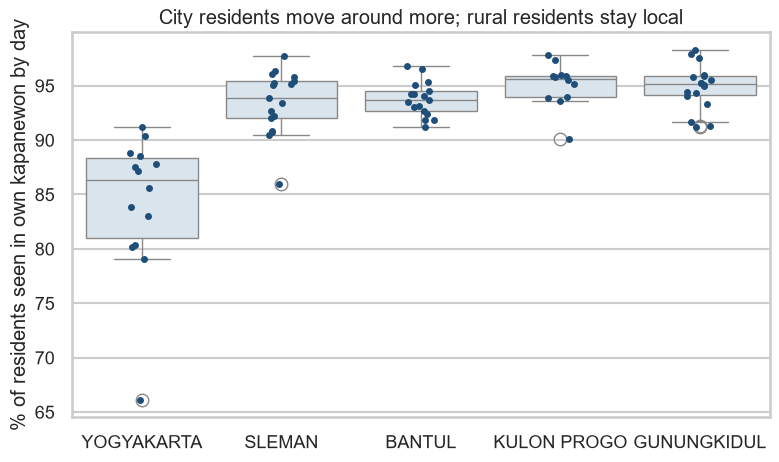

,origin_kab_kota,origin_kapanewon,self_containment_%
67,YOGYAKARTA,GONDOMANAN,66.113980
68,YOGYAKARTA,JETIS,79.046590
70,YOGYAKARTA,KRATON,80.195757
74,YOGYAKARTA,PAKUALAMAN,80.319081
66,YOGYAKARTA,GONDOKUSUMAN,82.990440
64,YOGYAKARTA,DANUREJAN,83.842041
65,YOGYAKARTA,GEDONGTENGEN,85.577362
60,SLEMAN,SEYEGAN,85.937652


In [3]:
selfc = (od[od["is_internal"]].groupby(["origin_kab_kota", "origin_kapanewon"])["share"].mean()
         .mul(100).rename("self_containment_%").reset_index())
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=selfc, x="origin_kab_kota", y="self_containment_%", order=jp.KAB_ORDER, ax=ax, color="#d6e4f0")
sns.stripplot(data=selfc, x="origin_kab_kota", y="self_containment_%", order=jp.KAB_ORDER, ax=ax,
              color="#1f4e79", size=5)
ax.set_xlabel("")
ax.set_ylabel("% of residents seen in own kapanewon by day")
ax.set_title("City residents move around more; rural residents stay local")
jp.savefig(fig, "05_self_containment.png")
plt.show()
selfc.sort_values("self_containment_%").head(8)

## 5.2 Trend: share of each regency's residents who visit Kota Yogyakarta (all 5 months)
Shares are robust to the shrinking sample, but Mar-Apr are marked as reduced quality.

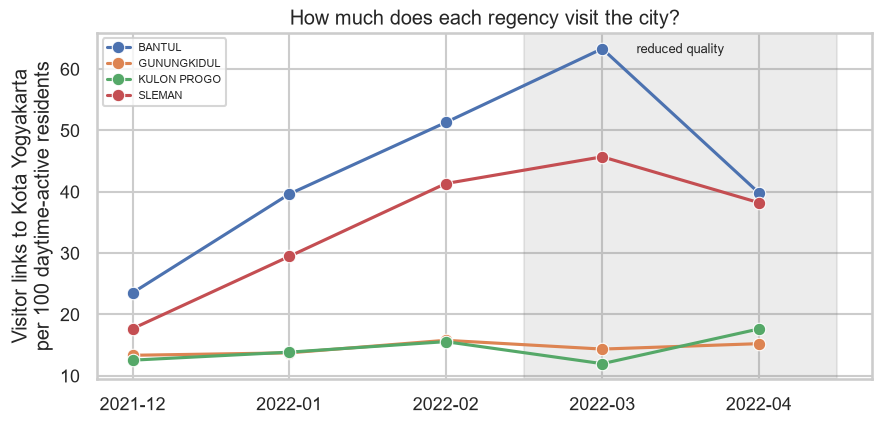

In [4]:
to_city = (od_all[(od_all["dest_kab_kota"] == "YOGYAKARTA") & (od_all["origin_kab_kota"] != "YOGYAKARTA")]
           .groupby(["month", "origin_kab_kota", "origin_code"])["n_maids"].sum().reset_index())
orig = jp.load_origins()
to_city = to_city.merge(orig[["month", "origin_code", "n_homed_maids_daytime"]], on=["month", "origin_code"])
trend = (to_city.groupby(["month", "origin_kab_kota"])[["n_maids", "n_homed_maids_daytime"]].sum()
         .assign(pct=lambda d: d["n_maids"] / d["n_homed_maids_daytime"] * 100).reset_index())
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=trend, x="month", y="pct", hue="origin_kab_kota", marker="o", ax=ax)
ax.axvspan(2.5, 4.5, color="grey", alpha=0.15)
ax.text(3.5, ax.get_ylim()[1] * 0.95, "reduced quality", ha="center", fontsize=9)
ax.set_ylabel("Visitor links to Kota Yogyakarta\nper 100 daytime-active residents")
ax.set_xlabel("")
ax.set_title("How much does each regency visit the city?")
ax.legend(title="", fontsize=8)
jp.savefig(fig, "05_trend_to_city.png")
plt.show()

## 5.3 Validation: are devices where people live?

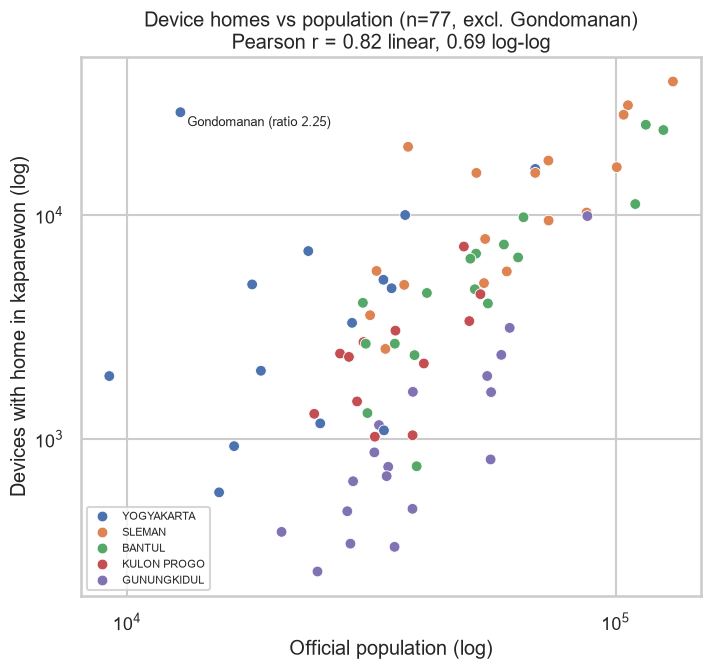

In [5]:
hv = jp.load_home_vs_population()
hv = hv[(hv["n_users"] > 0) & (hv["pop_actual"] > 0)]
no_gm = hv[hv["KEC_KAPN"] != "GONDOMANAN"]
r_lin = np.corrcoef(no_gm["n_users"], no_gm["pop_actual"])[0, 1]
r_log = np.corrcoef(np.log10(no_gm["n_users"]), np.log10(no_gm["pop_actual"]))[0, 1]

fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(data=hv, x="pop_actual", y="n_users", hue="KAB_KOTA", s=60, ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
for _, r in hv.nlargest(1, "ratio").iterrows():
    ax.annotate(f"{r['KEC_KAPN'].title()} (ratio {r['ratio']:.2f})", (r["pop_actual"], r["n_users"]),
                fontsize=9, xytext=(5, -10), textcoords="offset points")
ax.set_xlabel("Official population (log)")
ax.set_ylabel("Devices with home in kapanewon (log)")
ax.set_title(f"Device homes vs population (n={len(no_gm)}, excl. Gondomanan)\n"
             f"Pearson r = {r_lin:.2f} linear, {r_log:.2f} log-log")
ax.legend(title="", fontsize=8)
jp.savefig(fig, "05_validation_scatter.png")
plt.show()

## Key findings

**1. Self-containment (Dec 2021 - Feb 2022, 78 kapanewon)**
- Most self-contained (residents rarely leave by day): **Gedangsari** (Gunungkidul) 98.3%, **Panggang** (Gunungkidul) 98.0%, **Kokap** (Kulon Progo) 97.8%.
- Least self-contained (residents spread out the most): **Gondomanan** (Kota) 66.1%, **Jetis** (Kota) 79.0%, **Kraton** (Kota) 80.2%. All three are in Kota Yogyakarta.
- Median per regency: Kulon Progo 95.7%, Gunungkidul 95.2%, Sleman 93.8%, Bantul 93.7%, Kota Yogyakarta 86.4%. Rural regencies stay local; city residents move between kapanewon most.

**2. Residents visiting Kota Yogyakarta (visitor links per 100 daytime-active residents)**

| Regency | Dec 2021 | Jan 2022 | Feb 2022 | Mar 2022* | Apr 2022* |
|---|---|---|---|---|---|
| Bantul | 23.5 | 39.6 | 51.3 | 63.3 | 39.8 |
| Sleman | 17.7 | 29.5 | 41.3 | 45.7 | 38.2 |
| Gunungkidul | 13.3 | 13.7 | 15.8 | 14.4 | 15.2 |
| Kulon Progo | 12.5 | 13.9 | 15.6 | 12.0 | 17.6 |

\* reduced-quality OD months.
- Trend: Bantul and Sleman, the regencies bordering the city, show a strong upward trend from Dec to Feb (Bantul roughly doubles). Gunungkidul and Kulon Progo stay flat at about 13-16.
- Caution: this metric sums visits over destination kapanewon, so one device visiting several city kapanewon counts more than once. It is a connectivity index, not a percentage of people. The Dec-Feb rise may partly reflect the shrinking device panel, not only real behaviour.

**3. Validation: device homes vs official population**
- Pearson **r = 0.82** (linear) and **0.69** (log-log), n = 77 kapanewon, excluding Gondomanan. Including Gondomanan, r drops to 0.72.
- **Gondomanan is an outlier**: 28,874 devices with a home there vs 12,850 residents (ratio 2.25), while the median ratio is 0.09. Gondomanan (Malioboro / Beringharjo area) is a commercial and tourist hub, so many "home" detections are probably workers and visitors staying overnight there.
- Conclusion: the data tracks where people live well at the kapanewon level, but kapanewon in the city centre need care.


In [6]:
# @title Unduh semua grafik (Colab)
# Membuat figures.zip lalu mengunduhnya ke laptop, untuk slide dan untuk di-push ke GitHub.
if IN_COLAB:
    import shutil
    from google.colab import files as colab_files
    shutil.make_archive("/content/figures", "zip", "/content/jogjapulse/figures")
    colab_files.download("/content/figures.zip")
